## Modelling correlated sensor drift using a Gauss–Markov process

Previously, the measurement noise was modelled as independent Gaussian noise. We now extend the state vector to explicitly estimate a time-varying sensor bias, modelled as a first-order Gauss–Markov process.

### 1. Augmented state vector

The original state vector describes position, velocity and acceleration in two dimensions. We add two additional states representing the sensor bias in each measured position axis.

$$
\mathbf{x}_k =
\begin{bmatrix}
p_x \\
v_x \\
a_x \\
p_y \\
v_y \\
a_y \\
b_x \\
b_y
\end{bmatrix}
$$

Here, $b_x$ and $b_y$ are the time-varying measurement biases. These are not physical components of the object's motion; they are additional states that the filter estimates.

### 2. Gauss–Markov bias model

The bias evolves according to a first-order autoregressive process, AR(1):

$$
b_k = \alpha b_{k-1} + \eta_k
$$

where:

- $\alpha$ is the temporal correlation parameter, with $0 \leq \alpha < 1$ for positively correlated bias.
- $\eta_k$ is independent, zero-mean Gaussian process noise.
- A larger $\alpha$ produces more persistent, slowly varying bias.

To give the bias a stationary standard deviation of $\sigma_b$, the innovation variance is chosen as:

$$
\operatorname{Var}(\eta_k)
= \sigma_b^2(1-\alpha^2)
$$

Therefore:

$$
\eta_k \sim
\mathcal{N}\left(0,\sigma_b^2(1-\alpha^2)\right)
$$

This scaling ensures that the stationary bias variance remains $\sigma_b^2$ as $\alpha$ changes.

### 3. Updated transition matrix

The original six-state motion model remains unchanged. The two additional bias states evolve independently according to the AR(1) model.

The augmented transition matrix is:

$$
F =
\begin{bmatrix}
1 & \Delta t & \frac{1}{2}\Delta t^2 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & \Delta t & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 1 & \Delta t & \frac{1}{2}\Delta t^2 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & \Delta t & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & \alpha & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & \alpha
\end{bmatrix}
$$

The state prediction remains:

$$
\hat{\mathbf{x}}_{k|k-1}
= F\hat{\mathbf{x}}_{k-1|k-1}
$$

### 4. Updated measurement model

The sensor measures position, but its readings also contain the corresponding sensor bias and independent white measurement noise.

$$
\mathbf{z}_k = H\mathbf{x}_k + \boldsymbol{\epsilon}_k
$$

The augmented measurement matrix is:

$$
H =
\begin{bmatrix}
1 & 0 & 0 & 0 & 0 & 0 & 1 & 0 \\
0 & 0 & 0 & 1 & 0 & 0 & 0 & 1
\end{bmatrix}
$$

Equivalently, the two scalar measurement equations are:

$$
z_{x,k} = p_{x,k} + b_{x,k} + \epsilon_{x,k}
$$

$$
z_{y,k} = p_{y,k} + b_{y,k} + \epsilon_{y,k}
$$

The filter therefore observes the sum of true position and sensor bias, rather than being able to measure the bias directly.

### 5. Updated process-noise covariance

The augmented process-noise covariance is an $8 \times 8$ matrix.

$$
Q_{\mathrm{aug}} =
\begin{bmatrix}
Q_{\mathrm{motion}} & 0 \\
0 & Q_{\mathrm{bias}}
\end{bmatrix}
$$

Here, $Q_{\mathrm{motion}}$ is the existing $6 \times 6$ process-noise covariance, which describes uncertainty in the motion model.

The bias process-noise covariance is:

$$
Q_{\mathrm{bias}} =
\begin{bmatrix}
\sigma_b^2(1-\alpha^2) & 0 \\
0 & \sigma_b^2(1-\alpha^2)
\end{bmatrix}
$$

The zeros between the motion and bias blocks represent the assumption that their process-noise innovations are independent.

The covariance prediction is unchanged in form:

$$
P_{k|k-1} = FP_{k-1|k-1}F^T + Q_{\mathrm{aug}}
$$

### 6. Measurement-noise covariance

The measurement-noise covariance $R$ now represents only the independent white measurement noise. The correlated bias is modelled explicitly in the augmented state and must not also be counted in $R$.

For equal independent white measurement noise in both axes:

$$
R =
\begin{bmatrix}
\sigma_\epsilon^2 & 0 \\
0 & \sigma_\epsilon^2
\end{bmatrix}
$$

If the total measured noise has standard deviation $\sigma_{\mathrm{total}}$ and we assume that a fraction $f$ of its variance comes from the correlated bias, then:

$$
\sigma_b^2 = f\sigma_{\mathrm{total}}^2
$$

$$
\sigma_\epsilon^2 = (1-f)\sigma_{\mathrm{total}}^2
$$

This variance split assumes the bias and white-noise components are independent and that the bias is stationary. The fraction $f$ is a modelling assumption unless estimated from sensor data.

### 7. Kalman correction equations

The standard Kalman filter correction equations retain their original form, but use the augmented state and measurement matrices.

Innovation:

$$
\mathbf{y}_k =
\mathbf{z}_k - H\hat{\mathbf{x}}_{k|k-1}
$$

Innovation covariance:

$$
S_k = HP_{k|k-1}H^T + R
$$

Kalman gain:

$$
K_k = P_{k|k-1}H^TS_k^{-1}
$$

Updated state estimate:

$$
\hat{\mathbf{x}}_{k|k} =
\hat{\mathbf{x}}_{k|k-1} + K_k\mathbf{y}_k
$$

Updated state covariance:

$$
P_{k|k} =
(I-K_kH)P_{k|k-1}
$$

The estimated sensor biases are extracted from the final two elements of the updated state:

$$
\hat{\mathbf{b}}_k =
\begin{bmatrix}
\hat b_{x,k} \\
\hat b_{y,k}
\end{bmatrix}
$$

### 8. Interpretation and limitations

The augmented filter attempts to distinguish genuine object motion from slowly varying sensor bias. This is possible because the motion and bias states have different assumed temporal dynamics.

However, position and bias are not directly observed separately. If a change in sensor bias resembles genuine object motion, the filter may struggle to distinguish the two. The quality of the bias estimate therefore depends on the motion model, the bias dynamics, the process-noise covariances and the available measurements.

In this experiment, the ground-truth acceleration changes independently at each timestep, whereas the filter uses a continuous-white-jerk process model. This deliberate mismatch means the filter is not perfectly specified, even though the sensor bias dynamics are explicitly modelled.

Consequently, good position tracking does not necessarily imply good bias estimation. Position RMSE and bias RMSE should be evaluated separately.




In [1]:
import numpy as np
import matplotlib.pyplot as plt

# For noise model
from scipy import signal
from scipy.stats import norm

In [2]:
# Correlated first order auto-regressive noise (AR(1))
def GM_noise(n_steps, sig, alpha, seed = None):
    rng = np.random.default_rng(seed)
    
    noise = np.zeros(n_steps)
    noise[0] = rng.normal() * sig

    for k in range(1, n_steps):
        noise[k] =  alpha * noise[k-1] + rng.normal() * sig * np.sqrt(1 - alpha**2)
    return noise

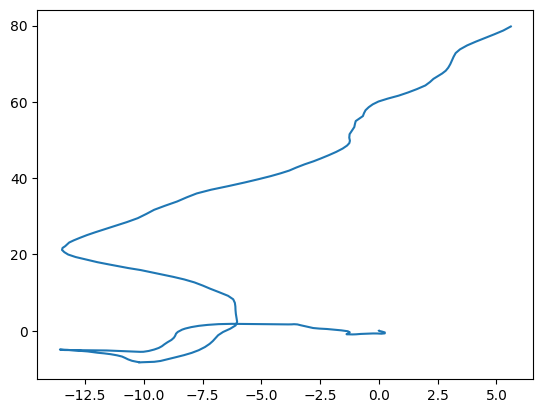

In [3]:
dt = 0.1
n_steps = 200

sig = 0.3 # total sigma
bias_alpha = 0.9
fraction_correlated = 0.8 # amount of noise that is correlated noise
q=10

bias_sig = sig * np.sqrt(fraction_correlated)  # sigma required for bias noise
sig_white = sig * np.sqrt(1 - fraction_correlated) # sigma required for white noise

def generate_gt(
    n_steps=100,
    dt=0.1,
    initial_position=(0.0, 0.0),
    initial_velocity=(0.0, 0.0),
    acceleration_std=0.5,
    bias_sig=0,
    bias_alpha=0,
    seed=174
):
    """
    Generate synthetic 2D motion with randomly changing acceleration.

    Returns
    -------
    output : ndarray, shape (n_steps, 6)
        State vector output
        Columns: [px, vx, ax, py, vy, ay]
    """
    rng = np.random.default_rng(seed)

    output = np.zeros((n_steps, 8)) # state vector

    # Initial state: [px, vx, ax, py, vy, ay, bx, by]
    output[0] = [
        initial_position[0], initial_velocity[0], 0.0,
        initial_position[1], initial_velocity[1], 0.0,
        0, 0
    ]

    bx = GM_noise(n_steps, bias_sig, bias_alpha, seed + 1)
    by = GM_noise(n_steps, bias_sig, bias_alpha, seed + 2)

    for k in range(1, n_steps):
        px, vx, _, py, vy, _, _, _ = output[k - 1]

        # Random acceleration in each axis
        ax = rng.normal(0, acceleration_std)
        ay = rng.normal(0, acceleration_std)
        
        # Update position and velocity
        output[k] = [
            px + vx * dt + 0.5 * ax * dt**2, vx + ax * dt, ax,
            py + vy * dt + 0.5 * ay * dt**2, vy + ay * dt, ay,
            bx[k], by[k]
        ]

    return output

gt_states = generate_gt(n_steps=n_steps, dt=0.1, initial_velocity=[-1,1], seed = 3, acceleration_std = q, bias_sig=bias_sig, bias_alpha=bias_alpha)
plt.plot(gt_states[:,0],gt_states[:,3],'-')

# Measurement
- I'm not sure how to normalise random noise and correlated noise into a unified noise with a given sigma
  

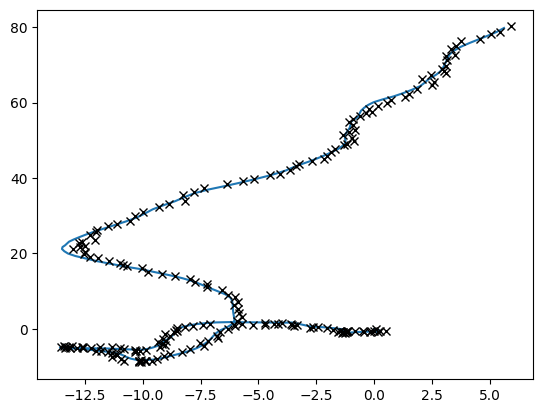

In [4]:
# Correlated bias already stored in ground-truth state
bias = gt_states[:, [6, 7]]

# Independent white measurement noise
rng = np.random.default_rng(175)
white_noise = rng.normal(0, sig_white, size=(n_steps, 2))

noise = bias + white_noise

meas_states = gt_states[:, [0, 3]] + noise
plt.plot(gt_states[:,0],gt_states[:,3],'-')
plt.plot(meas_states[:,0],meas_states[:,1],'kx')

In [5]:
noise.std()

np.float64(0.30451011221679763)

# Kalman: Accomodate for bias

In [6]:
dt = dt # timestep
q = 0.5 # process noise

bias_sig = bias_sig # noise 1st order correlation 
bias_alpha = bias_alpha # noise 1st order correlation 

v0 = 0 # initial state guess
a0 = 0 # initial state guess
b0 = 0 # initial bias guess

# Motion transition model
F = np.array([
    [1, dt, dt**2/2, 0, 0, 0, 0, 0],
    [0, 1, dt, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, dt, dt**2/2, 0, 0],
    [0, 0, 0, 0, 1, dt, 0, 0],
    [0, 0, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, bias_alpha, 0],
    [0, 0, 0, 0, 0, 0, 0, bias_alpha],
]) 

# Measurement mapping (measurements only measure positions )
# Measurement model will be z = H@x + v, where v has covariance matrix R
H = np.array([
    [1, 0, 0, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 0, 0, 0, 1],
])

# Process noise covariance
# "continuous white jerk noise".. assumes there's some smooth variation of accel.
Q = np.zeros((8, 8))
Q_1d = q*np.array([
    [dt**5/20, dt**4/8, dt**3/6],
    [dt**4/8, dt**3/3, dt**2/2],
    [dt**3/6, dt**2/2, dt]
])

Q[np.ix_([0, 1, 2], [0, 1, 2])] = Q_1d
Q[np.ix_([3, 4, 5], [3, 4, 5])] = Q_1d
Q[6,6] = bias_sig**2 * (1 - bias_alpha**2)
Q[7,7] = bias_sig**2 * (1 - bias_alpha**2)

# Measurement noise covariance
R = np.array([
    [sig_white**2, 0],
    [0, sig_white**2]
])

# Initial state guess
x_prev = np.array([
    [meas_states[0][0]],
    [v0],
    [a0],
    [meas_states[0][1]],
    [v0],
    [a0],
    [b0],
    [b0],
])

# Initial uncertainty
sig_p0 = 1
sig_v0 = 1
sig_a0 = 0

P_prev = np.diag([
    sig_p0**2,
    sig_v0**2,
    sig_a0**2,
    sig_p0**2,
    sig_v0**2,
    sig_a0**2,
    bias_sig**2,
    bias_sig**2
])

xs_list = [x_prev]
Ps_list = [P_prev]

zs_list = np.expand_dims(meas_states,1).transpose(0,2,1) ## need column vectors

# discard initial measurement, because we've directly used this z in prediction
for z in zs_list[1:]:
    ## 1. PREDICT STATE
    # x is state for step k, given state for k-1
    # F is transition model
    # x_prev is previous state
    x = F@x_prev
    
    # uncertainty
    # P here is the uncertainty (not probability) of state k given state k-1 happened
    # P_prev is uncertainty (not probability) in previous state
    # Q is the uncertainty due to unpredictable motion (random acceleration, for example)
    P = F@P_prev@F.T + Q
    
    ## 2. COMPARE WITH MEASUREMENT
    
    # y is "innovation" for step k
    # z is measurement for step k
    # x is state for step k, given state for k-1
    # H@x is predicted measurement
    y = z - H@x
    
    # Kalman gain
    # S is innovation covartiance for step k
    # P here is uncertainty (not probability) of state k given state k-1 happened
    # R is measurement noise covariance
    # K is Kalman gain
    S = H@P@H.T + R
    K = P@H.T@np.linalg.inv(S)
    
    ## 3. CORRECT THE STATE ESTIMATE
    # Updated estimate (x_new) equals predicted state (x) plus kalman gain (K) times innovation (y)
    x_new = x + K@y
    
    ## 4. UPDATE THE UNCERTAINTY
    # P here is the uncertainty (not probability) of state k given state k-1 happened
    
    P_new = P - K@H@P
    #    # "Joseph form", apparently has better floating point arithmetic
    #    I = np.eye(P.shape[0])
    #
    #    P_new = (
    #        (I - K @ H) @ P @ (I - K @ H).T
    #        + K @ R @ K.T
    #    )

    ## 5. PREP FOR NEXT ITERATION
    x_prev = x_new
    P_prev = P_new

    xs_list.append(x_new)
    Ps_list.append(P_new)

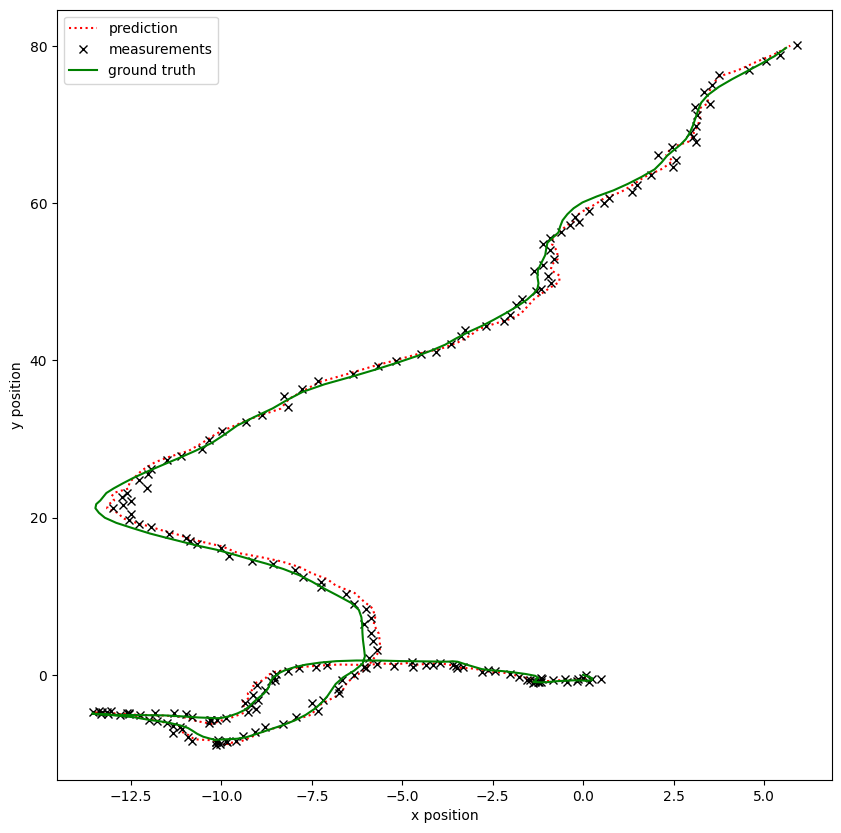

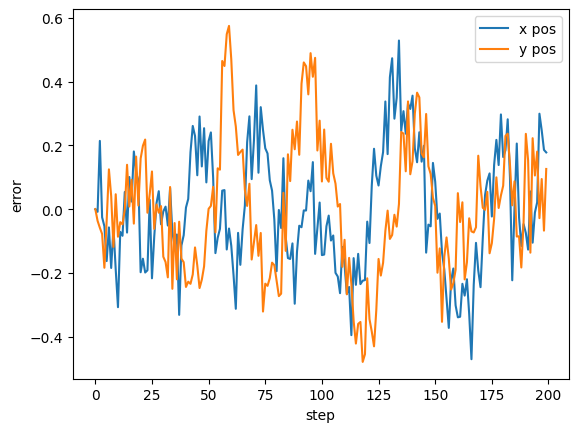

In [7]:
pred_state_x = np.array([_[0] for _ in xs_list])[:,0]
pred_state_y = np.array([_[3] for _ in xs_list])[:,0]
meas_state_x = np.array([_[0] for _ in meas_states])
meas_state_y = np.array([_[1] for _ in meas_states])
gt_state_x = np.array([_[0] for _ in gt_states])
gt_state_y = np.array([_[3] for _ in gt_states])

plt.figure(figsize = (10,10))
plt.plot(pred_state_x, pred_state_y , 'r:')
plt.plot(meas_state_x, meas_state_y , 'kx')
plt.plot(gt_state_x, gt_state_y , 'g-')
plt.xlabel("x position")
plt.ylabel("y position")
plt.legend(["prediction", "measurements", "ground truth"])

pos_err_x = meas_state_x - pred_state_x
pos_err_y = meas_state_y - pred_state_y

plt.figure()
plt.plot(pos_err_x)
plt.plot(pos_err_y)
plt.xlabel("step")
plt.ylabel("error")
plt.legend(["x pos", "y pos"])

In [8]:
rmse = np.sqrt(pos_err_x**2 + pos_err_y**2).mean()
print(rmse)

0.25264034477758823


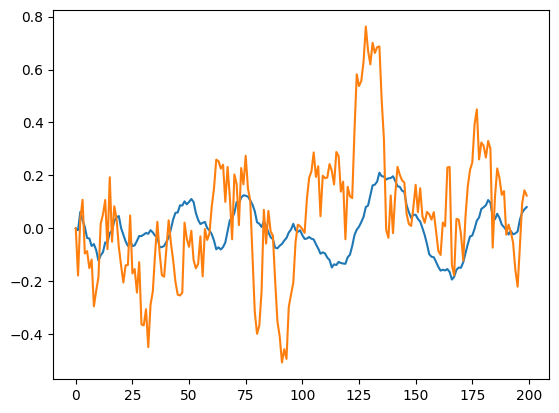

In [9]:
pred_bias_x = np.array([_[6] for _ in xs_list])[:,0]
pred_bias_y = np.array([_[7] for _ in xs_list])[:,0]
gt_bias_x = np.array([_[6] for _ in gt_states])
gt_bias_y = np.array([_[7] for _ in gt_states])

plt.plot(pred_bias_x)
plt.plot(gt_bias_x)

In [10]:
rmse = np.sqrt((pred_bias_x-gt_bias_x)**2 + (pred_bias_y-gt_bias_y)**2).mean()
print(rmse)

0.3378299047445328


In [11]:
gt_bias_y.std()

np.float64(0.2843256903093936)